# Эффективность малого GPT: эксперимент по методике Себастьяна Рашки

Ноутбук повторяет учебный маршрут книги **Build a Large Language Model (From Scratch)**: подготовка текста и сдвинутых пар input–target, причинное multi-head attention, сборка GPT, предобучение на следующем токене, генерация и оценка.

Требования проекта RoPE, RMSNorm и SwiGLU реализованы по официальному дополнению **Converting GPT to Llama**, а предлагаемый метод — по дополнениям **Sliding Window Attention** и **KV cache**. Код модели написан на PyTorch без готового класса Transformer.

- Официальный репозиторий книги: https://github.com/rasbt/LLMs-from-scratch
- GPT из глав 2–4: https://github.com/rasbt/LLMs-from-scratch/blob/main/ch04/01_main-chapter-code/gpt.py
- Предобучение из главы 5: https://github.com/rasbt/LLMs-from-scratch/blob/main/ch05/01_main-chapter-code/gpt_train.py
- Переход GPT → Llama: https://github.com/rasbt/LLMs-from-scratch/tree/main/ch05/07_gpt_to_llama
- Sliding Window Attention: https://github.com/rasbt/LLMs-from-scratch/tree/main/ch04/06_swa

Сравниваются модели одинакового размера: **Dense** с полным причинным attention и **Local** с причинным окном `W=128`. Это пилотное исследование; итоговый вывод требует полных запусков с seed 42, 43 и 44.


In [1]:
# Зависимости, которых нет в стандартном образе Colab.
!pip -q install "datasets>=3.0,<5" "sentencepiece>=0.2,<0.3" "pandas>=2.0" "matplotlib>=3.7"


## Структура эксперимента

1. **Глава 2:** WikiText → SentencePiece → пары `input_ids` и `target_ids`, сдвинутые на один токен.
2. **Глава 3:** Q, K, V и multi-head causal self-attention, реализованные явными tensor-операциями.
3. **Глава 4:** RMSNorm Pre-LN, SwiGLU, residual connections и полный decoder-only GPT.
4. **Глава 5:** cross-entropy, AdamW, цикл обучения, контроль validation loss и генерация образца.
5. **Дополнения:** RoPE, KV-cache и Sliding Window Attention.
6. **Исследование:** качество, FLOPs, latency, throughput, VRAM, KV-cache и scaling по длине контекста.

`smoke` проверяет код, `quick` проверяет снижение loss, `colab` выполняет полный набор метрик с доступным для T4 бюджетом, `full` оставлен для более мощной площадки. Промежуточное состояние обучения сохраняется на Google Drive.


In [2]:
from __future__ import annotations

import gc
import hashlib
import json
import math
import os
import platform
import random
import time
from array import array
from contextlib import nullcontext
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sentencepiece as spm
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from torch.utils.data import DataLoader, Dataset

torch.set_float32_matmul_precision("high")

RUN_MODE = "colab"                  # @param ["smoke", "quick", "colab", "full"]
ACTIVE_SEEDS_TEXT = "44"            # @param {type:"string"}
USE_GOOGLE_DRIVE = True             # @param {type:"boolean"}
RETRAIN_EXISTING = False            # @param {type:"boolean"}
RETEST_EXISTING = False             # @param {type:"boolean"}

REQUIRED_SEEDS = (42, 43, 44)
ACTIVE_SEEDS = tuple(int(value.strip()) for value in ACTIVE_SEEDS_TEXT.split(",") if value.strip())
assert ACTIVE_SEEDS and set(ACTIVE_SEEDS).issubset(REQUIRED_SEEDS)

EXPERIMENT_VERSION = "raschka_v1"
BENCHMARK_LENGTHS = (128, 256, 512, 1024, 2048)

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive/efficient_transformer_research")
    except ImportError:
        PROJECT_DIR = Path.cwd() / "efficient_transformer_research"
else:
    PROJECT_DIR = Path.cwd() / "efficient_transformer_research"

for subdir in ["tokenizer", "data_cache", "checkpoints", "results", "figures"]:
    (PROJECT_DIR / subdir).mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(ACTIVE_SEEDS[0])
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
print("PyTorch:", torch.__version__)
print("Project directory:", PROJECT_DIR)
print("Active seeds:", ACTIVE_SEEDS)


Mounted at /content/drive
Device: cuda
GPU: Tesla T4
CUDA: 13.0
PyTorch: 2.11.0+cu130
Project directory: /content/drive/MyDrive/efficient_transformer_research
Active seeds: (44,)


In [3]:
@dataclass
class RunConfig:
    dataset_name: str = "Salesforce/wikitext"
    dataset_config: str = "wikitext-103-raw-v1"
    vocab_size: int = 16_000
    seq_len: int = 512
    stride: int = 512
    window_size: int = 128
    d_model: int = 512
    n_heads: int = 8
    n_layers: int = 12
    d_ff: int = 1536
    dropout: float = 0.0
    learning_rate: float = 3e-4
    min_lr_ratio: float = 0.1
    weight_decay: float = 0.1
    betas: tuple[float, float] = (0.9, 0.95)
    grad_clip: float = 1.0
    warmup_ratio: float = 0.05
    batch_size: int = 2
    grad_accum_steps: int = 8
    num_workers: int = 2
    target_train_tokens: int = 2_457_600
    optimizer_steps: int = 0
    eval_batches: int | None = 200
    curve_eval_every: int = 50
    curve_eval_batches: int = 20
    log_every: int = 20
    max_train_docs: int | None = 250_000
    max_train_tokens: int | None = 20_000_000
    max_validation_tokens: int = 2_000_000
    tokenizer_train_lines: int = 250_000
    lambada_max_examples: int | None = 500
    bootstrap_repeats: int = 2_000
    benchmark_warmups: int = 5
    benchmark_repeats: int = 20
    decode_repeats: int = 8
    quality_scaling_targets: int = 256
    lambada_batch_size: int = 8
    checkpoint_every: int = 500


PRESETS = {
    "smoke": dict(
        target_train_tokens=20_480, eval_batches=5, curve_eval_every=10,
        curve_eval_batches=2, log_every=5, max_train_docs=10_000,
        max_train_tokens=1_000_000, max_validation_tokens=100_000,
        tokenizer_train_lines=10_000, grad_accum_steps=1,
        lambada_max_examples=30, bootstrap_repeats=500,
        benchmark_warmups=2, benchmark_repeats=5, decode_repeats=3,
        quality_scaling_targets=32,
    ),
    "quick": dict(),
    "colab": dict(
        target_train_tokens=8_388_608, eval_batches=None,
        curve_eval_every=250, curve_eval_batches=8, log_every=50,
        max_train_docs=250_000, max_train_tokens=20_000_000,
        max_validation_tokens=1_000_000, tokenizer_train_lines=250_000,
        grad_accum_steps=4, lambada_max_examples=None,
        bootstrap_repeats=5_000, benchmark_warmups=5,
        benchmark_repeats=20, decode_repeats=8,
        quality_scaling_targets=128, lambada_batch_size=8,
        checkpoint_every=500,
    ),
    "full": dict(
        target_train_tokens=50_000_000, eval_batches=None,
        curve_eval_every=250, curve_eval_batches=32, log_every=50,
        max_train_docs=None, max_train_tokens=100_000_000,
        max_validation_tokens=5_000_000, tokenizer_train_lines=500_000,
        lambada_max_examples=None, bootstrap_repeats=10_000,
        benchmark_warmups=10, benchmark_repeats=50, decode_repeats=15,
        quality_scaling_targets=1_024,
    ),
}

cfg = RunConfig(**{**asdict(RunConfig()), **PRESETS[RUN_MODE]})
assert cfg.d_model % cfg.n_heads == 0
assert 0 < cfg.window_size <= cfg.seq_len
assert 0 < cfg.stride <= cfg.seq_len

TOKENS_PER_OPTIMIZER_STEP = cfg.batch_size * cfg.grad_accum_steps * cfg.seq_len
cfg.optimizer_steps = math.ceil(cfg.target_train_tokens / TOKENS_PER_OPTIMIZER_STEP)
PLANNED_TRAIN_TOKENS = cfg.optimizer_steps * TOKENS_PER_OPTIMIZER_STEP

print(json.dumps(asdict(cfg), ensure_ascii=False, indent=2))
print("Tokens per optimizer step:", f"{TOKENS_PER_OPTIMIZER_STEP:,}")
print("Optimizer steps:", f"{cfg.optimizer_steps:,}")
print("Actual planned tokens per model:", f"{PLANNED_TRAIN_TOKENS:,}")


{
  "dataset_name": "Salesforce/wikitext",
  "dataset_config": "wikitext-103-raw-v1",
  "vocab_size": 16000,
  "seq_len": 512,
  "stride": 512,
  "window_size": 128,
  "d_model": 512,
  "n_heads": 8,
  "n_layers": 12,
  "d_ff": 1536,
  "dropout": 0.0,
  "learning_rate": 0.0003,
  "min_lr_ratio": 0.1,
  "weight_decay": 0.1,
  "betas": [
    0.9,
    0.95
  ],
  "grad_clip": 1.0,
  "warmup_ratio": 0.05,
  "batch_size": 2,
  "grad_accum_steps": 4,
  "num_workers": 2,
  "target_train_tokens": 8388608,
  "optimizer_steps": 2048,
  "eval_batches": null,
  "curve_eval_every": 250,
  "curve_eval_batches": 8,
  "log_every": 50,
  "max_train_docs": 250000,
  "max_train_tokens": 20000000,
  "max_validation_tokens": 1000000,
  "tokenizer_train_lines": 250000,
  "lambada_max_examples": null,
  "bootstrap_repeats": 5000,
  "benchmark_warmups": 5,
  "benchmark_repeats": 20,
  "decode_repeats": 8,
  "quality_scaling_targets": 128,
  "lambada_batch_size": 8,
  "checkpoint_every": 500
}
Tokens per optim

## Глава 2. Подготовка текста

Как у Рашки, языковая модель получает пары последовательностей, сдвинутых на один токен. Адаптация под проект: вместо GPT-2 BPE используется собственный SentencePiece BPE на 16 000 токенов, а вместо одной книги — официальные train/validation split WikiText-103. Токен `eos` добавляется один раз на статью WikiText.


In [4]:
raw = load_dataset(cfg.dataset_name, cfg.dataset_config)
train_split = raw["train"]
valid_split = raw["validation"]
print(raw)

sp_prefix = PROJECT_DIR / "tokenizer" / f"wikitext_bpe_{cfg.vocab_size}_lines{cfg.tokenizer_train_lines}"
sp_model_path = Path(str(sp_prefix) + ".model")
sp_corpus_path = PROJECT_DIR / "tokenizer" / f"sentencepiece_corpus_{cfg.tokenizer_train_lines}.txt"

if not sp_model_path.exists():
    with sp_corpus_path.open("w", encoding="utf-8") as f:
        written = 0
        for row in train_split:
            text = row["text"].strip()
            if not text:
                continue
            f.write(text.replace("\n", " ") + "\n")
            written += 1
            if written >= cfg.tokenizer_train_lines:
                break
    spm.SentencePieceTrainer.train(
        input=str(sp_corpus_path),
        model_prefix=str(sp_prefix),
        vocab_size=cfg.vocab_size,
        model_type="bpe",
        character_coverage=0.9995,
        pad_id=0,
        unk_id=1,
        bos_id=2,
        eos_id=3,
        byte_fallback=True,
        hard_vocab_limit=False,
        num_threads=os.cpu_count() or 2,
    )

sp = spm.SentencePieceProcessor(model_file=str(sp_model_path))
assert sp.vocab_size() == cfg.vocab_size
print("Tokenizer vocabulary:", sp.vocab_size())
print(sp.encode("A small Transformer is ready.", out_type=str))


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-103-raw-v1/test-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-103-raw-v1/test-00000-of-00001.(…): downloading bytes:           |  0.00B            

wikitext-103-raw-v1/train-00000-of-00002(…): reconstructing file:   0%|          |  0.00B /  157MB            

wikitext-103-raw-v1/train-00000-of-00002(…): downloading bytes:           |  0.00B            

...

wikitext-103-raw-v1/validation-00000-of-(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/1801350 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 1801350
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
Tokenizer vocabulary: 16000
['▁A', '▁small', '▁Trans', 'form', 'er', '▁is', '▁ready', '.']


In [5]:
def is_article_title(text: str) -> bool:
    text = text.strip()
    return text.startswith("= ") and text.endswith(" =") and not text.startswith("==")


def iter_wikitext_documents(split):
    current = []
    for row in split:
        text = row["text"].strip()
        if not text:
            continue
        if is_article_title(text) and current:
            yield "\n".join(current)
            current = [text]
        else:
            current.append(text)
    if current:
        yield "\n".join(current)


def encode_split(split, token_limit: int | None, doc_limit: int | None = None):
    ids = array("H")
    documents = 0
    truncated_document = False

    for document in iter_wikitext_documents(split):
        if doc_limit is not None and documents >= doc_limit:
            break
        encoded = sp.encode(document, out_type=int)
        if not encoded:
            continue

        if token_limit is not None:
            remaining = token_limit - len(ids)
            if remaining <= 1:
                break
            if len(encoded) + 1 > remaining:
                encoded = encoded[: remaining - 1]
                truncated_document = True

        ids.extend(encoded)
        ids.append(sp.eos_id())
        documents += 1

        if truncated_document or (token_limit is not None and len(ids) >= token_limit):
            break

    tensor = torch.tensor(ids, dtype=torch.int32)
    stats = {
        "documents": documents,
        "tokens_after_tokenization": int(tensor.numel()),
        "eos_tokens": documents,
        "eos_policy": "one_eos_per_wikitext_article",
        "last_document_truncated_by_token_limit": truncated_document,
    }
    return tensor, stats


cache_tag = (
    f"{EXPERIMENT_VERSION}_{RUN_MODE}_v{cfg.vocab_size}"
    f"_tok{cfg.max_train_tokens}_val{cfg.max_validation_tokens}"
    f"_lines{cfg.tokenizer_train_lines}_article_eos"
)


def load_or_encode(split, split_name, token_limit, doc_limit=None):
    token_path = PROJECT_DIR / "data_cache" / f"{split_name}_{cache_tag}.pt"
    meta_path = PROJECT_DIR / "data_cache" / f"{split_name}_{cache_tag}.json"
    if token_path.exists() and meta_path.exists():
        tokens = torch.load(token_path, map_location="cpu", weights_only=True)
        stats = json.loads(meta_path.read_text(encoding="utf-8"))
    else:
        tokens, stats = encode_split(split, token_limit, doc_limit)
        torch.save(tokens, token_path)
        meta_path.write_text(json.dumps(stats, ensure_ascii=False, indent=2), encoding="utf-8")
    assert stats["tokens_after_tokenization"] == tokens.numel()
    return tokens, stats


train_tokens, train_encoding_stats = load_or_encode(
    train_split, "train", cfg.max_train_tokens, cfg.max_train_docs
)
valid_tokens, validation_encoding_stats = load_or_encode(
    valid_split, "validation", cfg.max_validation_tokens
)

print("Train encoding:", json.dumps(train_encoding_stats, ensure_ascii=False, indent=2))
print("Validation encoding:", json.dumps(validation_encoding_stats, ensure_ascii=False, indent=2))


Train encoding: {
  "documents": 50674,
  "tokens_after_tokenization": 20000000,
  "eos_tokens": 50674,
  "eos_policy": "one_eos_per_wikitext_article",
  "last_document_truncated_by_token_limit": true
}
Validation encoding: {
  "documents": 620,
  "tokens_after_tokenization": 255180,
  "eos_tokens": 620,
  "eos_policy": "one_eos_per_wikitext_article",
  "last_document_truncated_by_token_limit": false
}


In [6]:
class GPTDatasetV1(Dataset):
    def __init__(self, token_ids: torch.Tensor, max_length: int, stride: int):
        self.token_ids = token_ids
        self.max_length = max_length
        self.stride = stride
        self.start_positions = list(range(0, max(0, token_ids.numel() - max_length), stride))

    def __len__(self):
        return len(self.start_positions)

    def __getitem__(self, index):
        start = self.start_positions[index]
        input_chunk = self.token_ids[start : start + self.max_length].long()
        target_chunk = self.token_ids[start + 1 : start + self.max_length + 1].long()
        return input_chunk, target_chunk


def create_dataloader_v1(dataset, batch_size, shuffle, drop_last, seed):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=cfg.num_workers,
        pin_memory=DEVICE.type == "cuda",
        persistent_workers=cfg.num_workers > 0,
        generator=generator if shuffle else None,
    )


train_dataset = GPTDatasetV1(train_tokens, cfg.seq_len, cfg.stride)
valid_dataset = GPTDatasetV1(valid_tokens, cfg.seq_len, cfg.stride)
assert len(train_dataset) > 0 and len(valid_dataset) > 0


def make_loaders(seed: int):
    train_loader = create_dataloader_v1(
        train_dataset, cfg.batch_size, shuffle=True, drop_last=True, seed=seed
    )
    valid_loader = create_dataloader_v1(
        valid_dataset, cfg.batch_size, shuffle=False, drop_last=False, seed=seed
    )
    return train_loader, valid_loader


probe_train_loader, probe_valid_loader = make_loaders(ACTIVE_SEEDS[0])
loader_stats = {
    "dataset_class": "GPTDatasetV1",
    "max_length": cfg.seq_len,
    "stride": cfg.stride,
    "train_sequences": len(train_dataset),
    "validation_sequences": len(valid_dataset),
    "train_batches": len(probe_train_loader),
    "validation_batches": len(probe_valid_loader),
    "validation_target_tokens_available": len(valid_dataset) * cfg.seq_len,
}
print(json.dumps(loader_stats, ensure_ascii=False, indent=2))
first_x, first_y = train_dataset[0]
assert torch.equal(first_x[1:], first_y[:-1])
print("Input-target shift check: passed")
del probe_train_loader, probe_valid_loader, first_x, first_y


{
  "dataset_class": "GPTDatasetV1",
  "max_length": 512,
  "stride": 512,
  "train_sequences": 39062,
  "validation_sequences": 498,
  "train_batches": 19531,
  "validation_batches": 249,
  "validation_target_tokens_available": 254976
}
Input-target shift check: passed


## Главы 3–4 и дополнение GPT → Llama. Модель с нуля

Следуя учебному подходу книги, Q, K, V, causal mask, softmax и объединение голов записаны явно. Проектная архитектура использует RoPE, RMSNorm Pre-LN и SwiGLU. Dense и Local отличаются только областью внимания; число обучаемых параметров одинаково.


In [7]:
@dataclass
class GPTConfig:
    vocab_size: int = 16_000
    d_model: int = 512
    n_heads: int = 8
    n_layers: int = 12
    d_ff: int = 1536
    max_seq_len: int = 2048
    dropout: float = 0.0
    attention_type: str = "dense"
    window_size: int = 128
    rope_theta: float = 10_000.0
    rms_eps: float = 1e-6


class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.scale = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x):
        dtype = x.dtype
        x_float = x.float()
        norm = x_float * torch.rsqrt(x_float.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return (norm * self.scale.float()).to(dtype)


class RotaryEmbedding(nn.Module):
    def __init__(self, head_dim: int, max_seq_len: int, theta: float = 10_000.0):
        super().__init__()
        assert head_dim % 2 == 0
        inv_freq = 1.0 / (theta ** (torch.arange(0, head_dim, 2).float() / head_dim))
        positions = torch.arange(max_seq_len).float()
        angles = torch.outer(positions, inv_freq)
        self.register_buffer("cos", angles.cos().repeat_interleave(2, dim=-1), persistent=False)
        self.register_buffer("sin", angles.sin().repeat_interleave(2, dim=-1), persistent=False)

    def forward(self, positions: torch.Tensor, dtype: torch.dtype):
        return (
            self.cos[positions][None, None].to(dtype),
            self.sin[positions][None, None].to(dtype),
        )


def rotate_half(x):
    pairs = x.float().reshape(*x.shape[:-1], -1, 2)
    rotated = torch.stack((-pairs[..., 1], pairs[..., 0]), dim=-1).flatten(-2)
    return rotated.to(x.dtype)


def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin


class MultiHeadAttention(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        assert config.d_model % config.n_heads == 0
        self.d_out = config.d_model
        self.num_heads = config.n_heads
        self.head_dim = config.d_model // config.n_heads
        self.attention_type = config.attention_type
        self.window_size = config.window_size
        self.W_query = nn.Linear(config.d_model, config.d_model, bias=False)
        self.W_key = nn.Linear(config.d_model, config.d_model, bias=False)
        self.W_value = nn.Linear(config.d_model, config.d_model, bias=False)
        self.out_proj = nn.Linear(config.d_model, config.d_model, bias=False)
        self.dropout = nn.Dropout(config.dropout)
        self.rope = RotaryEmbedding(self.head_dim, config.max_seq_len, config.rope_theta)
        mask = torch.triu(torch.ones(config.max_seq_len, config.max_seq_len, dtype=torch.bool), diagonal=1)
        self.register_buffer("causal_mask", mask, persistent=False)

    def _split_heads(self, tensor):
        batch_size, num_tokens, _ = tensor.shape
        return tensor.view(batch_size, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)

    def _dense_attention(self, queries, keys, values):
        num_tokens = queries.shape[2]
        attn_scores = queries @ keys.transpose(2, 3)
        attn_scores = attn_scores / math.sqrt(self.head_dim)
        mask = self.causal_mask[:num_tokens, :num_tokens]
        attn_scores = attn_scores.masked_fill(mask[None, None], torch.finfo(attn_scores.dtype).min)
        attn_weights = self.dropout(torch.softmax(attn_scores.float(), dim=-1).to(queries.dtype))
        return attn_weights @ values

    def _local_attention(self, queries, keys, values):
        _, _, num_tokens, _ = queries.shape
        window = min(self.window_size, num_tokens)
        keys_padded = F.pad(keys, (0, 0, window - 1, 0))
        values_padded = F.pad(values, (0, 0, window - 1, 0))
        key_windows = keys_padded.unfold(2, window, 1).permute(0, 1, 2, 4, 3)
        value_windows = values_padded.unfold(2, window, 1).permute(0, 1, 2, 4, 3)
        attn_scores = torch.einsum("bhtd,bhtwd->bhtw", queries, key_windows)
        attn_scores = attn_scores / math.sqrt(self.head_dim)
        query_positions = torch.arange(num_tokens, device=queries.device)[:, None]
        offsets = torch.arange(window, device=queries.device)[None, :] - (window - 1)
        valid = query_positions + offsets >= 0
        attn_scores = attn_scores.masked_fill(
            ~valid[None, None], torch.finfo(attn_scores.dtype).min
        )
        attn_weights = self.dropout(torch.softmax(attn_scores.float(), dim=-1).to(queries.dtype))
        return torch.einsum("bhtw,bhtwd->bhtd", attn_weights, value_windows)

    def forward(self, x, past_kv=None, use_cache=False, position_offset=0):
        batch_size, num_tokens, _ = x.shape
        queries = self._split_heads(self.W_query(x))
        keys = self._split_heads(self.W_key(x))
        values = self._split_heads(self.W_value(x))

        positions = torch.arange(
            position_offset, position_offset + num_tokens, device=x.device
        )
        cos, sin = self.rope(positions, queries.dtype)
        queries = apply_rope(queries, cos, sin)
        keys = apply_rope(keys, cos, sin)

        if past_kv is None:
            if self.attention_type == "dense":
                context = self._dense_attention(queries, keys, values)
            else:
                context = self._local_attention(queries, keys, values)
            keys_all, values_all = keys, values
        else:
            assert num_tokens == 1
            past_keys, past_values = past_kv
            keys_all = torch.cat((past_keys, keys), dim=2)
            values_all = torch.cat((past_values, values), dim=2)
            if self.attention_type == "local":
                keys_all = keys_all[:, :, -self.window_size :]
                values_all = values_all[:, :, -self.window_size :]
            attn_scores = queries @ keys_all.transpose(2, 3)
            attn_scores = attn_scores / math.sqrt(self.head_dim)
            attn_weights = torch.softmax(attn_scores.float(), dim=-1).to(queries.dtype)
            context = attn_weights @ values_all

        new_cache = None
        if use_cache:
            if self.attention_type == "local":
                keep = max(1, self.window_size - 1)
                new_cache = (keys_all[:, :, -keep:], values_all[:, :, -keep:])
            else:
                new_cache = (keys_all, values_all)

        context = context.transpose(1, 2).contiguous().view(batch_size, num_tokens, self.d_out)
        return self.out_proj(context), new_cache


class FeedForward(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.gate = nn.Linear(config.d_model, config.d_ff, bias=False)
        self.up = nn.Linear(config.d_model, config.d_ff, bias=False)
        self.down = nn.Linear(config.d_ff, config.d_model, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))


class TransformerBlock(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.att = MultiHeadAttention(config)
        self.ff = FeedForward(config)
        self.norm1 = RMSNorm(config.d_model, config.rms_eps)
        self.norm2 = RMSNorm(config.d_model, config.rms_eps)
        self.drop_shortcut = nn.Dropout(config.dropout)

    def forward(self, x, past_kv=None, use_cache=False, position_offset=0):
        shortcut = x
        attn_out, new_cache = self.att(
            self.norm1(x), past_kv=past_kv,
            use_cache=use_cache, position_offset=position_offset,
        )
        x = shortcut + self.drop_shortcut(attn_out)
        x = x + self.drop_shortcut(self.ff(self.norm2(x)))
        return x, new_cache


class GPTModel(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.config = config
        self.tok_emb = nn.Embedding(config.vocab_size, config.d_model)
        self.trf_blocks = nn.ModuleList([TransformerBlock(config) for _ in range(config.n_layers)])
        self.final_norm = RMSNorm(config.d_model, config.rms_eps)
        self.out_head = nn.Linear(config.d_model, config.vocab_size, bias=False)
        self.apply(self._init_weights)
        self.out_head.weight = self.tok_emb.weight

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, in_idx, targets=None, past_key_values=None, use_cache=False, position_offset=0):
        x = self.tok_emb(in_idx)
        new_past = [] if use_cache else None
        for layer_index, block in enumerate(self.trf_blocks):
            layer_past = None if past_key_values is None else past_key_values[layer_index]
            x, layer_cache = block(
                x, past_kv=layer_past, use_cache=use_cache,
                position_offset=position_offset,
            )
            if use_cache:
                new_past.append(layer_cache)
        logits = self.out_head(self.final_norm(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.flatten(0, 1), targets.flatten())
        return {"logits": logits, "loss": loss, "past_key_values": new_past}


SmallGPT = GPTModel


def make_gpt_config(attention_type: str) -> GPTConfig:
    return GPTConfig(
        vocab_size=cfg.vocab_size,
        d_model=cfg.d_model,
        n_heads=cfg.n_heads,
        n_layers=cfg.n_layers,
        d_ff=cfg.d_ff,
        max_seq_len=max(BENCHMARK_LENGTHS),
        dropout=cfg.dropout,
        attention_type=attention_type,
        window_size=cfg.window_size,
    )


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


for attention_type in ("dense", "local"):
    test_model = GPTModel(make_gpt_config(attention_type))
    n_params = count_parameters(test_model)
    print(attention_type, f"{n_params:,} parameters ({n_params / 1e6:.2f}M)")
    assert 45_000_000 <= n_params <= 55_000_000
    assert test_model.out_head.weight.data_ptr() == test_model.tok_emb.weight.data_ptr()
    del test_model
gc.collect()


tiny_dense_cfg = GPTConfig(
    vocab_size=128, d_model=32, n_heads=4, n_layers=2, d_ff=96,
    max_seq_len=16, attention_type="dense", window_size=16, dropout=0.0,
)
tiny_local_cfg = replace(tiny_dense_cfg, attention_type="local")
seed_everything(123)
tiny_dense = GPTModel(tiny_dense_cfg).eval()
tiny_local = GPTModel(tiny_local_cfg).eval()
tiny_local.load_state_dict(tiny_dense.state_dict())
tiny_input = torch.randint(0, 128, (2, 16))
with torch.inference_mode():
    dense_logits = tiny_dense(tiny_input)["logits"]
    local_logits = tiny_local(tiny_input)["logits"]
torch.testing.assert_close(dense_logits, local_logits, rtol=1e-4, atol=1e-5)
print("Dense/local equality check for W=T: passed")
del tiny_dense, tiny_local, dense_logits, local_logits
gc.collect()


dense 49,099,264 parameters (49.10M)
local 49,099,264 parameters (49.10M)
Dense/local equality check for W=T: passed


0

## Глава 5. Loss, оценка, обучение и генерация

Функции `calc_loss_batch`, `calc_loss_loader`, `evaluate_model`, `train_model_simple`, `text_to_token_ids`, `token_ids_to_text` и `generate_text_simple` повторяют структуру главы 5. Для исследовательского протокола добавлены mixed precision, gradient accumulation, clipping, cosine schedule с warmup, полный учёт токенов и сохранение checkpoint.


In [8]:
def autocast_context():
    if DEVICE.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=AMP_DTYPE)
    return nullcontext()


def calc_loss_batch(input_batch, target_batch, model):
    with autocast_context():
        return model(input_batch, target_batch)["loss"]


@torch.inference_mode()
def calc_loss_loader(data_loader, model, num_batches=None):
    was_training = model.training
    model.eval()
    if len(data_loader) == 0:
        raise ValueError("DataLoader is empty")
    batches_to_process = len(data_loader) if num_batches is None else min(num_batches, len(data_loader))
    loss_sum = 0.0
    tokens_processed = 0
    batches_processed = 0

    for batch_index, (input_batch, target_batch) in enumerate(data_loader):
        if batch_index >= batches_to_process:
            break
        input_batch = input_batch.to(DEVICE, non_blocking=True)
        target_batch = target_batch.to(DEVICE, non_blocking=True)
        loss = calc_loss_batch(input_batch, target_batch, model)
        batch_tokens = target_batch.numel()
        loss_sum += float(loss) * batch_tokens
        tokens_processed += batch_tokens
        batches_processed += 1

    if was_training:
        model.train()
    mean_loss = loss_sum / tokens_processed
    return {
        "loss": mean_loss,
        "perplexity": float(math.exp(min(20.0, mean_loss))),
        "batches_available": len(data_loader),
        "batches_processed": batches_processed,
        "tokens_processed": tokens_processed,
    }


def evaluate_model(model, train_loader, val_loader, eval_iter):
    train_stats = calc_loss_loader(train_loader, model, eval_iter)
    val_stats = calc_loss_loader(val_loader, model, eval_iter)
    return train_stats, val_stats


def evaluate(model, loader, max_batches=None):
    stats = calc_loss_loader(loader, model, max_batches)
    return {
        "validation_loss": stats["loss"],
        "perplexity": stats["perplexity"],
        "validation_batches_available": stats["batches_available"],
        "validation_batches_processed": stats["batches_processed"],
        "validation_tokens_processed": stats["tokens_processed"],
    }


def text_to_token_ids(text):
    token_ids = sp.encode(text, out_type=int)
    if not token_ids:
        token_ids = [sp.bos_id()]
    return torch.tensor(token_ids, dtype=torch.long)[None]


def token_ids_to_text(token_ids):
    return sp.decode(token_ids.squeeze(0).tolist())


@torch.inference_mode()
def generate_text_simple(model, idx, max_new_tokens, context_size):
    was_training = model.training
    model.eval()
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with autocast_context():
            logits = model(idx_cond)["logits"]
        idx_next = torch.argmax(logits[:, -1, :], dim=-1, keepdim=True)
        idx = torch.cat((idx, idx_next), dim=1)
    if was_training:
        model.train()
    return idx


def make_optimizer(model):
    return torch.optim.AdamW(
        model.parameters(),
        lr=cfg.learning_rate,
        weight_decay=cfg.weight_decay,
        betas=cfg.betas,
    )


def make_scheduler(optimizer):
    warmup_steps = max(1, round(cfg.optimizer_steps * cfg.warmup_ratio))

    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, cfg.optimizer_steps - warmup_steps)
        cosine = 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress)))
        return cfg.min_lr_ratio + (1.0 - cfg.min_lr_ratio) * cosine

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def infinite_batches(loader):
    while True:
        yield from loader


def save_training_progress(
    path, model, optimizer, scheduler, scaler, global_step,
    tokens_seen, micro_batches, log_rows, elapsed_seconds,
    peak_training_vram_bytes, resume_count,
):
    temporary_path = path.with_suffix(".tmp")
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "global_step": global_step,
        "tokens_seen": tokens_seen,
        "micro_batches": micro_batches,
        "log_rows": log_rows,
        "elapsed_seconds": elapsed_seconds,
        "peak_training_vram_bytes": peak_training_vram_bytes,
        "resume_count": resume_count,
    }, temporary_path)
    os.replace(temporary_path, path)
    print("Progress checkpoint:", path, "step", global_step)


def train_model_simple(model, train_loader, val_loader, optimizer, scheduler, progress_path):
    stream = infinite_batches(train_loader)
    scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")
    start_step = 0
    tokens_seen = 0
    micro_batches = 0
    elapsed_before = 0.0
    previous_peak_vram = 0
    resume_count = 0

    if progress_path.exists() and not RETRAIN_EXISTING:
        progress = torch.load(progress_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(progress["model_state"])
        optimizer.load_state_dict(progress["optimizer_state"])
        scheduler.load_state_dict(progress["scheduler_state"])
        scaler.load_state_dict(progress["scaler_state"])
        start_step = int(progress["global_step"])
        tokens_seen = int(progress["tokens_seen"])
        micro_batches = int(progress["micro_batches"])
        log_rows = progress["log_rows"]
        elapsed_before = float(progress["elapsed_seconds"])
        previous_peak_vram = int(progress.get("peak_training_vram_bytes") or 0)
        resume_count = int(progress.get("resume_count", 0)) + 1
        print("Resuming from optimizer step", start_step)
    else:
        train_stats, val_stats = evaluate_model(
            model, train_loader, val_loader, min(cfg.curve_eval_batches, len(val_loader))
        )
        log_rows = [{
            "optimizer_step": 0,
            "micro_batches_processed": 0,
            "training_tokens_processed": 0,
            "train_loss": train_stats["loss"],
            "validation_sample_loss": val_stats["loss"],
            "learning_rate": 0.0,
            "grad_norm": None,
            "elapsed_seconds": 0.0,
            "training_tokens_per_second": None,
        }]

    model.train()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    session_start = time.perf_counter()

    for global_step in range(start_step + 1, cfg.optimizer_steps + 1):
        optimizer.zero_grad(set_to_none=True)
        accumulated_loss = 0.0

        for _ in range(cfg.grad_accum_steps):
            input_batch, target_batch = next(stream)
            input_batch = input_batch.to(DEVICE, non_blocking=True)
            target_batch = target_batch.to(DEVICE, non_blocking=True)
            loss = calc_loss_batch(input_batch, target_batch, model) / cfg.grad_accum_steps
            scaler.scale(loss).backward()
            accumulated_loss += float(loss.detach())
            tokens_seen += target_batch.numel()
            micro_batches += 1

        scaler.unscale_(optimizer)
        grad_norm = float(torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip))
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        should_log = global_step == 1 or global_step % cfg.log_every == 0 or global_step == cfg.optimizer_steps
        should_eval = global_step == 1 or global_step % cfg.curve_eval_every == 0 or global_step == cfg.optimizer_steps
        if should_log or should_eval:
            elapsed = elapsed_before + time.perf_counter() - session_start
            validation_sample_loss = None
            if should_eval:
                validation_sample_loss = calc_loss_loader(
                    val_loader, model, min(cfg.curve_eval_batches, len(val_loader))
                )["loss"]
            row = {
                "optimizer_step": global_step,
                "micro_batches_processed": micro_batches,
                "training_tokens_processed": tokens_seen,
                "train_loss": accumulated_loss,
                "validation_sample_loss": validation_sample_loss,
                "learning_rate": scheduler.get_last_lr()[0],
                "grad_norm": grad_norm,
                "elapsed_seconds": elapsed,
                "training_tokens_per_second": tokens_seen / elapsed,
            }
            log_rows.append(row)
            print(row)

        if global_step % cfg.checkpoint_every == 0 and global_step < cfg.optimizer_steps:
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
                session_peak = torch.cuda.max_memory_allocated()
            else:
                session_peak = 0
            checkpoint_started = time.perf_counter()
            save_training_progress(
                progress_path, model, optimizer, scheduler, scaler, global_step,
                tokens_seen, micro_batches, log_rows,
                elapsed_before + time.perf_counter() - session_start,
                max(previous_peak_vram, session_peak), resume_count,
            )
            session_start += time.perf_counter() - checkpoint_started

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        session_peak = torch.cuda.max_memory_allocated()
    else:
        session_peak = 0
    training_seconds = elapsed_before + time.perf_counter() - session_start
    return log_rows, {
        "training_seconds": training_seconds,
        "training_tokens": tokens_seen,
        "micro_batches_processed": micro_batches,
        "peak_training_vram_bytes": max(previous_peak_vram, session_peak) or None,
        "resume_count": resume_count,
    }


def run_paths(attention_type: str, seed: int):
    stem = f"{attention_type}_{RUN_MODE}_{EXPERIMENT_VERSION}_seed{seed}"
    return {
        "checkpoint": PROJECT_DIR / "checkpoints" / f"{stem}.pt",
        "summary": PROJECT_DIR / "results" / f"summary_{stem}.json",
        "log": PROJECT_DIR / "results" / f"training_{stem}.csv",
        "progress": PROJECT_DIR / "checkpoints" / f"progress_{stem}.pt",
    }


def train_one(attention_type: str, seed: int):
    paths = run_paths(attention_type, seed)
    if paths["checkpoint"].exists() and paths["summary"].exists() and not RETRAIN_EXISTING:
        print("Using existing checkpoint:", paths["checkpoint"])
        return json.loads(paths["summary"].read_text(encoding="utf-8"))

    seed_everything(seed)
    train_loader, valid_loader = make_loaders(seed)
    model = GPTModel(make_gpt_config(attention_type)).to(DEVICE)
    optimizer = make_optimizer(model)
    scheduler = make_scheduler(optimizer)
    if RETRAIN_EXISTING and paths["progress"].exists():
        paths["progress"].unlink()
    log_rows, training = train_model_simple(
        model, train_loader, valid_loader, optimizer, scheduler, paths["progress"]
    )
    validation = evaluate(model, valid_loader, cfg.eval_batches)
    prompt = text_to_token_ids("The").to(DEVICE)
    generated = generate_text_simple(model, prompt, max_new_tokens=30, context_size=cfg.seq_len)
    sample_text = token_ids_to_text(generated.cpu())

    checkpoint = {
        "model_state": {key: value.detach().cpu() for key, value in model.state_dict().items()},
        "model_config": asdict(model.config),
        "run_config": asdict(cfg),
        "seed": seed,
        "attention_type": attention_type,
        "experiment_version": EXPERIMENT_VERSION,
        "methodology": "Raschka chapters 2-5 plus GPT-to-Llama, KV-cache and SWA supplements",
    }
    torch.save(checkpoint, paths["checkpoint"])
    pd.DataFrame(log_rows).to_csv(paths["log"], index=False)

    summary = {
        "attention_type": attention_type,
        "run_mode": RUN_MODE,
        "experiment_version": EXPERIMENT_VERSION,
        "seed": seed,
        "parameters": count_parameters(model),
        "model_memory_fp32_bytes": count_parameters(model) * 4,
        "model_memory_fp16_bytes": count_parameters(model) * 2,
        "optimizer_steps": cfg.optimizer_steps,
        "target_training_tokens": cfg.target_train_tokens,
        **training,
        "training_tokens_per_second": training["training_tokens"] / training["training_seconds"],
        "validation_tokens_after_tokenization": validation_encoding_stats["tokens_after_tokenization"],
        "generated_sample": sample_text,
        **validation,
        "checkpoint": str(paths["checkpoint"]),
        "training_log": str(paths["log"]),
    }
    paths["summary"].write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Generated sample:", sample_text.replace("\n", " "))
    if paths["progress"].exists():
        paths["progress"].unlink()

    del model, optimizer, scheduler
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return summary


In [9]:
for seed in ACTIVE_SEEDS:
    train_one("dense", seed)
    train_one("local", seed)


def load_completed_summaries():
    completed = {}
    for seed in REQUIRED_SEEDS:
        pair = {}
        for attention_type in ("dense", "local"):
            path = run_paths(attention_type, seed)["summary"]
            if path.exists():
                pair[attention_type] = json.loads(path.read_text(encoding="utf-8"))
        if len(pair) == 2:
            completed[seed] = pair
    return completed


summaries_by_seed = load_completed_summaries()
all_summaries = [summaries_by_seed[seed][kind] for seed in summaries_by_seed for kind in ("dense", "local")]
print("Completed seeds:", sorted(summaries_by_seed))
print("Missing seeds:", sorted(set(REQUIRED_SEEDS) - set(summaries_by_seed)))


/tmp/ipykernel_1418/3793814411.py:141: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")


{'optimizer_step': 1, 'micro_batches_processed': 4, 'training_tokens_processed': 4096, 'train_loss': 9.785659790039062, 'validation_sample_loss': 9.763522148132324, 'learning_rate': 5.88235294117647e-06, 'grad_norm': 3.7955150604248047, 'elapsed_seconds': 0.610906373999967, 'training_tokens_per_second': 6704.791723126172}
{'optimizer_step': 50, 'micro_batches_processed': 200, 'training_tokens_processed': 204800, 'train_loss': 7.9085259437561035, 'validation_sample_loss': None, 'learning_rate': 0.00015, 'grad_norm': 1.243386149406433, 'elapsed_seconds': 14.717995228000007, 'training_tokens_per_second': 13914.938605930625}
{'optimizer_step': 100, 'micro_batches_processed': 400, 'training_tokens_processed': 409600, 'train_loss': 7.235996127128601, 'validation_sample_loss': None, 'learning_rate': 0.00029705882352941177, 'grad_norm': 0.6625191569328308, 'elapsed_seconds': 29.20703460300001, 'training_tokens_per_second': 14024.018719035852}
{'optimizer_step': 150, 'micro_batches_processed': 

In [10]:
quality_runs = pd.DataFrame(all_summaries)
quality_runs["peak_training_vram_gib"] = quality_runs["peak_training_vram_bytes"] / 2**30
quality_runs["training_minutes"] = quality_runs["training_seconds"] / 60
quality_runs.to_csv(
    PROJECT_DIR / "results" / f"quality_runs_{RUN_MODE}_{EXPERIMENT_VERSION}.csv",
    index=False,
)

aggregate_columns = [
    "validation_loss", "perplexity", "training_minutes",
    "training_tokens_per_second", "peak_training_vram_gib",
]
quality_aggregate = quality_runs.groupby("attention_type")[aggregate_columns].agg(["mean", "std", "count"])
quality_aggregate.to_csv(
    PROJECT_DIR / "results" / f"quality_aggregate_{RUN_MODE}_{EXPERIMENT_VERSION}.csv"
)

paired_quality_rows = []
for seed, pair in summaries_by_seed.items():
    ratio = pair["local"]["perplexity"] / pair["dense"]["perplexity"]
    paired_quality_rows.append({
        "seed": seed,
        "dense_perplexity": pair["dense"]["perplexity"],
        "local_perplexity": pair["local"]["perplexity"],
        "local_over_dense_perplexity": ratio,
        "comparable_at_5_percent": ratio <= 1.05,
    })
paired_quality = pd.DataFrame(paired_quality_rows)
paired_quality.to_csv(
    PROJECT_DIR / "results" / f"paired_quality_{RUN_MODE}_{EXPERIMENT_VERSION}.csv",
    index=False,
)

display(quality_runs[[
    "seed", "attention_type", "optimizer_steps", "training_tokens",
    "validation_batches_available", "validation_batches_processed",
    "validation_tokens_processed", "validation_loss", "perplexity",
    "training_minutes", "training_tokens_per_second", "peak_training_vram_gib",
]])
display(quality_aggregate)
display(paired_quality)


,seed,attention_type,optimizer_steps,training_tokens,validation_batches_available,validation_batches_processed,validation_tokens_processed,validation_loss,perplexity,training_minutes,training_tokens_per_second,peak_training_vram_gib
0,42,dense,2048,8388608,249,249,254976,5.266150,193.668966,10.284862,13593.778780,1.714172
1,42,local,2048,8388608,249,249,254976,5.237113,188.126210,53.770137,2600.144626,4.465520
2,43,dense,2048,8388608,249,249,254976,5.268352,194.095874,10.457967,13368.767920,1.714172
3,43,local,2048,8388608,249,249,254976,5.239307,188.539313,55.352569,2525.811102,4.465520
4,44,dense,2048,8388608,249,249,254976,5.266170,193.672870,10.504654,13309.351163,1.714172
5,44,local,2048,8388608,249,249,254976,5.249196,190.413117,54.540001,2563.442079,4.465520


validation_loss                  perplexity                  \
                          mean       std count        mean       std count   
attention_type                                                               
dense                 5.266891  0.001265     3  193.812570  0.245356     3   
local                 5.241872  0.006437     3  189.026213  1.218725     3   

               training_minutes                 training_tokens_per_second  \
                           mean       std count                       mean   
attention_type                                                               
dense                 10.415828  0.115797     3               13423.965954   
local                 54.554236  0.791312     3                2563.132602   

                                 peak_training_vram_gib             
                       std count                   mean  std count  
attention_type                                                      
dense           150.032945     3               1.714172  0.0     3  
local            37.167729     3               4.465520  0.0     3

,seed,dense_perplexity,local_perplexity,local_over_dense_perplexity,comparable_at_5_percent
0,42,193.668966,188.126210,0.971380,True
1,43,194.095874,188.539313,0.971372,True
2,44,193.672870,190.413117,0.983169,True


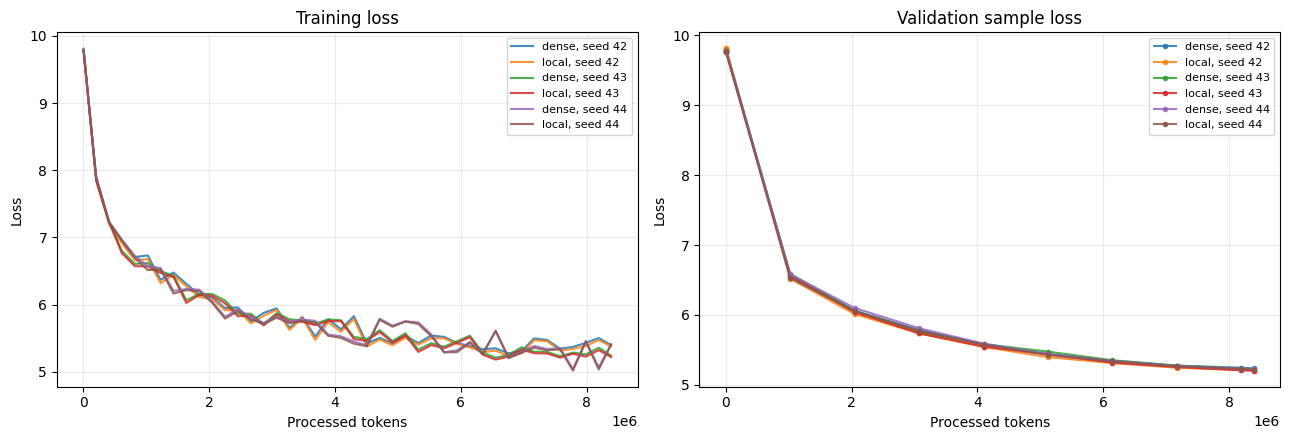

Saved: /content/drive/MyDrive/efficient_transformer_research/figures/learning_curves_colab_raschka_v1.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for summary in all_summaries:
    log = pd.read_csv(summary["training_log"])
    label = f'{summary["attention_type"]}, seed {summary["seed"]}'
    axes[0].plot(log["training_tokens_processed"], log["train_loss"], label=label, alpha=0.85)
    valid_points = log.dropna(subset=["validation_sample_loss"])
    axes[1].plot(
        valid_points["training_tokens_processed"],
        valid_points["validation_sample_loss"],
        marker="o", markersize=3, label=label, alpha=0.85,
    )

axes[0].set(title="Training loss", xlabel="Processed tokens", ylabel="Loss")
axes[1].set(title="Validation sample loss", xlabel="Processed tokens", ylabel="Loss")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
fig.tight_layout()
curve_path = PROJECT_DIR / "figures" / f"learning_curves_{RUN_MODE}_{EXPERIMENT_VERSION}.png"
fig.savefig(curve_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", curve_path)


## Zero-shot оценка LAMBADA

В режиме `full` используется весь доступный test split. Для exact match указывается интервал Уилсона, для точности токенов — bootstrap-интервал. Парные bootstrap-интервалы показывают разницу Local − Dense на одинаковых примерах.


In [12]:
lambada = load_dataset("EleutherAI/lambada_openai", "default", split="test")


def load_model_from_checkpoint(path: str | Path):
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    model = SmallGPT(GPTConfig(**checkpoint["model_config"]))
    model.load_state_dict(checkpoint["model_state"])
    model.eval().to(DEVICE)
    if DEVICE.type == "cuda":
        model.half()
    return model


def wilson_interval(successes: int, total: int, z: float = 1.959964):
    if total == 0:
        return (float("nan"), float("nan"))
    p = successes / total
    denominator = 1.0 + z * z / total
    center = (p + z * z / (2 * total)) / denominator
    radius = z * math.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / denominator
    return center - radius, center + radius


def bootstrap_mean_interval(values, repeats: int, seed: int):
    values = np.asarray(values, dtype=np.float64)
    rng = np.random.default_rng(seed)
    sampled_means = np.empty(repeats, dtype=np.float64)
    chunk = 250
    for start in range(0, repeats, chunk):
        count = min(chunk, repeats - start)
        indices = rng.integers(0, len(values), size=(count, len(values)))
        sampled_means[start : start + count] = values[indices].mean(axis=1)
    return np.quantile(sampled_means, [0.025, 0.5, 0.975]).tolist()


def paired_bootstrap_interval(a, b, repeats: int, seed: int):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    assert len(a) == len(b)
    return bootstrap_mean_interval(b - a, repeats, seed)


@torch.inference_mode()
def lambada_metrics(model, max_examples: int | None):
    records = []
    skipped = 0
    for example in lambada:
        if max_examples is not None and len(records) >= max_examples:
            break
        text = example["text"].strip()
        if " " not in text:
            skipped += 1
            continue
        context_text, target_word = text.rsplit(" ", 1)
        context_ids = sp.encode(context_text, out_type=int)
        target_ids = sp.encode(" " + target_word, out_type=int)
        if not target_ids or len(target_ids) >= cfg.seq_len:
            skipped += 1
            continue
        context_ids = context_ids[-max(1, cfg.seq_len - len(target_ids)) :]
        if not context_ids:
            context_ids = [sp.bos_id()]
        records.append({
            "input_ids": context_ids + target_ids[:-1],
            "target_ids": target_ids,
            "prediction_start": len(context_ids) - 1,
        })

    exact = []
    per_example_token_accuracy = []
    token_hits = 0
    target_tokens = 0
    for batch_start in range(0, len(records), cfg.lambada_batch_size):
        batch = records[batch_start : batch_start + cfg.lambada_batch_size]
        max_length = max(len(record["input_ids"]) for record in batch)
        x = torch.full(
            (len(batch), max_length), sp.pad_id(), dtype=torch.long, device=DEVICE
        )
        for row, record in enumerate(batch):
            ids = torch.tensor(record["input_ids"], dtype=torch.long, device=DEVICE)
            x[row, : len(ids)] = ids
        with autocast_context():
            logits = model(x)["logits"]

        for row, record in enumerate(batch):
            start = record["prediction_start"]
            targets = record["target_ids"]
            predictions = logits[row, start : start + len(targets)].argmax(dim=-1).cpu().tolist()
            matches = np.asarray([int(pred == target) for pred, target in zip(predictions, targets)])
            exact.append(int(matches.all() and len(matches) == len(targets)))
            per_example_token_accuracy.append(float(matches.mean()))
            token_hits += int(matches.sum())
            target_tokens += len(matches)

    exact_ci = wilson_interval(sum(exact), len(exact))
    token_ci = bootstrap_mean_interval(
        per_example_token_accuracy, cfg.bootstrap_repeats, ACTIVE_SEEDS[0]
    )
    result = {
        "examples_available": len(lambada),
        "examples_used": len(exact),
        "examples_skipped": skipped,
        "lambada_batch_size": cfg.lambada_batch_size,
        "target_tokens": target_tokens,
        "exact_match": float(np.mean(exact)),
        "exact_match_ci_low": exact_ci[0],
        "exact_match_ci_high": exact_ci[1],
        "target_token_accuracy_micro": token_hits / target_tokens,
        "target_token_accuracy_macro": float(np.mean(per_example_token_accuracy)),
        "target_token_accuracy_macro_ci_low": token_ci[0],
        "target_token_accuracy_macro_ci_high": token_ci[2],
    }
    return result, exact, per_example_token_accuracy


def evaluate_lambada_pair(seed: int, pair):
    path = PROJECT_DIR / "results" / f"lambada_{RUN_MODE}_{EXPERIMENT_VERSION}_seed{seed}.json"
    if path.exists() and not RETEST_EXISTING:
        return json.loads(path.read_text(encoding="utf-8"))

    rows = []
    vectors = {}
    for attention_type in ("dense", "local"):
        model = load_model_from_checkpoint(pair[attention_type]["checkpoint"])
        result, exact, token_accuracy = lambada_metrics(model, cfg.lambada_max_examples)
        rows.append({"seed": seed, "attention_type": attention_type, **result})
        vectors[attention_type] = (exact, token_accuracy)
        del model
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    paired = {
        "seed": seed,
        "exact_match_local_minus_dense_ci": paired_bootstrap_interval(
            vectors["dense"][0], vectors["local"][0], cfg.bootstrap_repeats, seed
        ),
        "token_accuracy_local_minus_dense_ci": paired_bootstrap_interval(
            vectors["dense"][1], vectors["local"][1], cfg.bootstrap_repeats, seed + 1000
        ),
    }
    payload = {"rows": rows, "paired": paired}
    path.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")
    return payload


lambada_payloads = [
    evaluate_lambada_pair(seed, pair) for seed, pair in summaries_by_seed.items()
]
lambada_rows = [row for payload in lambada_payloads for row in payload["rows"]]
lambada_table = pd.DataFrame(lambada_rows)
lambada_table.to_csv(
    PROJECT_DIR / "results" / f"lambada_{RUN_MODE}_{EXPERIMENT_VERSION}.csv",
    index=False,
)
display(lambada_table)
display(pd.DataFrame([payload["paired"] for payload in lambada_payloads]))

if RUN_MODE in ("colab", "full"):
    assert all(
        row["examples_used"] + row["examples_skipped"] == row["examples_available"]
        for row in lambada_rows
    )


README.md:   0%|          | 0.00/5.47k [00:00<?, ?B/s]

default/test/default.parquet: reconstructing file:   0%|          |  0.00B / 1.16MB            

default/test/default.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/5153 [00:00<?, ? examples/s]

,seed,attention_type,examples_available,examples_used,examples_skipped,lambada_batch_size,target_tokens,exact_match,exact_match_ci_low,exact_match_ci_high,target_token_accuracy_micro,target_token_accuracy_macro,target_token_accuracy_macro_ci_low,target_token_accuracy_macro_ci_high
0,42,dense,5153,5153,0,8,8652,0.000000,-5.421011e-20,0.000745,0.021845,0.013368,0.011307,0.015479
1,42,local,5153,5153,0,8,8652,0.000000,-5.421011e-20,0.000745,0.021729,0.013945,0.011910,0.016184
2,43,dense,5153,5153,0,8,8652,0.000194,3.425748e-05,0.001099,0.020111,0.012126,0.010151,0.014193
3,43,local,5153,5153,0,8,8652,0.000000,-5.421011e-20,0.000745,0.020573,0.012639,0.010629,0.014677
4,44,dense,5153,5153,0,8,8652,0.000000,-5.421011e-20,0.000745,0.024619,0.015716,0.013482,0.018038
5,44,local,5153,5153,0,8,8652,0.000388,1.064439e-04,0.001414,0.023578,0.014915,0.012660,0.017185


,seed,exact_match_local_minus_dense_ci,token_accuracy_local_minus_dense_ci
0,42,"[0.0, 0.0, 0.0]","[-0.0014303041224252167, 0.0005930433496899633..."
1,43,"[-0.0005821851348728896, -0.000194061711624296...","[-0.0012530211880105143, 0.0005123442441509586..."
2,44,"[0.0, 0.00038812342324859306, 0.00097030855812...","[-0.002661167185230837, -0.0008245554820365611..."


## Дополнения KV-cache и Sliding Window Attention. Вычислительное масштабирование

Prefill и decode измеряются раздельно. Для времени приводятся медиана и межквартильный диапазон. FLOPs являются теоретической оценкой; latency и VRAM измеряются на фактическом устройстве.


In [13]:
def theoretical_flops(attention_type: str, seq_len: int, batch_size: int = 1):
    d, d_ff, layers, vocab = cfg.d_model, cfg.d_ff, cfg.n_layers, cfg.vocab_size
    window = min(cfg.window_size, seq_len)
    projections = batch_size * layers * 8 * seq_len * d * d
    swiglu = batch_size * layers * 6 * seq_len * d * d_ff
    attention = batch_size * layers * 4 * seq_len * (
        seq_len if attention_type == "dense" else window
    ) * d
    lm_head = batch_size * 2 * seq_len * d * vocab
    return {
        "projection_flops": projections,
        "swiglu_flops": swiglu,
        "attention_flops": attention,
        "lm_head_flops": lm_head,
        "total_forward_flops": projections + swiglu + attention + lm_head,
    }


def tensor_bytes(tensor):
    return tensor.numel() * tensor.element_size()


def cache_bytes(past_key_values):
    return sum(tensor_bytes(key) + tensor_bytes(value) for key, value in past_key_values)


def distribution(values, prefix):
    values = np.asarray(values, dtype=np.float64)
    return {
        f"{prefix}_median": float(np.median(values)),
        f"{prefix}_q25": float(np.quantile(values, 0.25)),
        f"{prefix}_q75": float(np.quantile(values, 0.75)),
    }


@torch.inference_mode()
def benchmark_prefill(model, attention_type: str, lengths=BENCHMARK_LENGTHS):
    rows = []
    for length in lengths:
        x = torch.randint(0, cfg.vocab_size, (1, length), device=DEVICE)
        try:
            for _ in range(cfg.benchmark_warmups):
                with autocast_context():
                    warmup_out = model(x, use_cache=True)
                del warmup_out

            times = []
            for _ in range(cfg.benchmark_repeats):
                if DEVICE.type == "cuda":
                    torch.cuda.synchronize()
                start = time.perf_counter()
                with autocast_context():
                    out = model(x, use_cache=True)
                if DEVICE.type == "cuda":
                    torch.cuda.synchronize()
                times.append(time.perf_counter() - start)
                del out

            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
                torch.cuda.reset_peak_memory_stats()
            with autocast_context():
                measured = model(x, use_cache=True)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            peak_vram = torch.cuda.max_memory_allocated() if DEVICE.type == "cuda" else None
            kv_bytes = cache_bytes(measured["past_key_values"])
            del measured

            latency_ms = np.asarray(times) * 1000
            throughput = length / np.asarray(times)
            rows.append({
                "context_length": length,
                "benchmark_warmups": cfg.benchmark_warmups,
                "benchmark_repeats": cfg.benchmark_repeats,
                **distribution(latency_ms, "prefill_latency_ms"),
                **distribution(throughput, "prefill_tokens_per_second"),
                "prefill_kv_cache_bytes": kv_bytes,
                "peak_prefill_vram_bytes": peak_vram,
                **theoretical_flops(attention_type, length),
            })
        except torch.cuda.OutOfMemoryError:
            rows.append({"context_length": length, "out_of_memory": True})
            torch.cuda.empty_cache()
    return rows


@torch.inference_mode()
def benchmark_decode(model, prompt_length=256, new_tokens=64):
    prompt = torch.randint(0, cfg.vocab_size, (1, prompt_length), device=DEVICE)

    def run_once():
        with autocast_context():
            out = model(prompt, use_cache=True, position_offset=0)
        past = out["past_key_values"]
        kv_bytes = cache_bytes(past)
        token = out["logits"][:, -1:].argmax(dim=-1)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        for step in range(new_tokens):
            with autocast_context():
                out = model(
                    token, past_key_values=past, use_cache=True,
                    position_offset=prompt_length + step,
                )
            past = out["past_key_values"]
            token = out["logits"][:, -1:].argmax(dim=-1)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        return time.perf_counter() - start, kv_bytes

    for _ in range(min(2, cfg.benchmark_warmups)):
        run_once()
    times, kv_bytes = [], None
    for _ in range(cfg.decode_repeats):
        elapsed, kv_bytes = run_once()
        times.append(elapsed)

    throughput = new_tokens / np.asarray(times)
    return {
        "prompt_length": prompt_length,
        "generated_tokens": new_tokens,
        "decode_repeats": cfg.decode_repeats,
        **distribution(throughput, "decode_tokens_per_second"),
        "kv_cache_bytes_after_prefill": kv_bytes,
    }


def benchmark_seed(seed: int, pair):
    compute_path = PROJECT_DIR / "results" / f"compute_{RUN_MODE}_{EXPERIMENT_VERSION}_seed{seed}.csv"
    decode_path = PROJECT_DIR / "results" / f"decode_{RUN_MODE}_{EXPERIMENT_VERSION}_seed{seed}.csv"
    if compute_path.exists() and decode_path.exists() and not RETEST_EXISTING:
        return pd.read_csv(compute_path), pd.read_csv(decode_path)

    compute_rows, decode_rows = [], []
    for attention_type in ("dense", "local"):
        model = load_model_from_checkpoint(pair[attention_type]["checkpoint"])
        for row in benchmark_prefill(model, attention_type):
            compute_rows.append({"seed": seed, "attention_type": attention_type, **row})
        decode_rows.append({
            "seed": seed, "attention_type": attention_type,
            **benchmark_decode(model),
        })
        del model
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    compute_table = pd.DataFrame(compute_rows)
    decode_table = pd.DataFrame(decode_rows)
    compute_table.to_csv(compute_path, index=False)
    decode_table.to_csv(decode_path, index=False)
    return compute_table, decode_table


benchmark_tables, decode_tables = [], []
for seed, pair in summaries_by_seed.items():
    compute_seed, decode_seed = benchmark_seed(seed, pair)
    benchmark_tables.append(compute_seed)
    decode_tables.append(decode_seed)

benchmark_table = pd.concat(benchmark_tables, ignore_index=True)
decode_table = pd.concat(decode_tables, ignore_index=True)
benchmark_table.to_csv(
    PROJECT_DIR / "results" / f"computational_scaling_{RUN_MODE}_{EXPERIMENT_VERSION}.csv",
    index=False,
)
decode_table.to_csv(
    PROJECT_DIR / "results" / f"decode_{RUN_MODE}_{EXPERIMENT_VERSION}.csv",
    index=False,
)
display(benchmark_table)
display(decode_table)


,seed,attention_type,context_length,benchmark_warmups,benchmark_repeats,prefill_latency_ms_median,prefill_latency_ms_q25,prefill_latency_ms_q75,prefill_tokens_per_second_median,prefill_tokens_per_second_q25,prefill_tokens_per_second_q75,prefill_kv_cache_bytes,peak_prefill_vram_bytes,projection_flops,swiglu_flops,attention_flops,lm_head_flops,total_forward_flops
0,42,dense,128,5,20,16.570605,16.196601,17.070977,7724.634061,7498.109852,7902.893603,3145728,182478848,3221225472,7247757312,402653184,2097152000,12968787968
1,42,dense,256,5,20,17.399289,16.961265,18.076510,14713.249591,14162.026461,15094.618573,6291456,189885440,6442450944,14495514624,1610612736,4194304000,26742882304
2,42,dense,512,5,20,17.243406,17.112894,17.492355,29692.578901,29270.171530,29919.015302,12582912,212239360,12884901888,28991029248,6442450944,8388608000,56706990080
3,42,dense,1024,5,20,28.119279,28.062297,28.184185,36416.296581,36332.432984,36490.244846,25165824,287351808,25769803776,57982058496,25769803776,16777216000,126298882048
4,42,dense,2048,5,20,91.704213,91.543942,91.834496,22332.670709,22300.988245,22371.769992,50331648,572843008,51539607552,115964116992,103079215104,33554432000,304137371648
5,42,local,128,5,20,19.390450,19.210500,19.584803,6601.195015,6535.834443,6663.022842,3121152,196422656,3221225472,7247757312,402653184,2097152000,12968787968
6,42,local,256,5,20,20.880048,20.495814,21.110860,12260.508826,12126.467294,12490.630313,3121152,217708544,6442450944,14495514624,805306368,4194304000,25937575936
7,42,local,512,5,20,37.240209,36.971625,37.433321,13748.582664,13677.714539,13848.458211,3121152,260280320,12884901888,28991029248,1610612736,8388608000,51875151872
8,42,local,1024,5,20,72.933011,72.760686,73.257249,14040.285393,13978.144652,14073.544560,3121152,345950208,25769803776,57982058496,3221225472,16777216000,103750303744
9,42,local,2048,5,20,150.839040,150.497969,151.406570,13577.387117,13526.493762,13608.157291,3121152,520953856,51539607552,115964116992,6442450944,33554432000,207500607488


,seed,attention_type,prompt_length,generated_tokens,decode_repeats,decode_tokens_per_second_median,decode_tokens_per_second_q25,decode_tokens_per_second_q75,kv_cache_bytes_after_prefill
0,42,dense,256,64,8,67.702515,67.419439,67.988206,6291456
1,42,local,256,64,8,65.490176,65.061392,65.966549,3121152
2,43,dense,256,64,8,67.810997,66.109566,68.125765,6291456
3,43,local,256,64,8,65.352935,64.599294,66.121782,3121152
4,44,dense,256,64,8,65.408897,64.336004,66.076608,6291456
5,44,local,256,64,8,61.842354,61.118962,62.379846,3121152


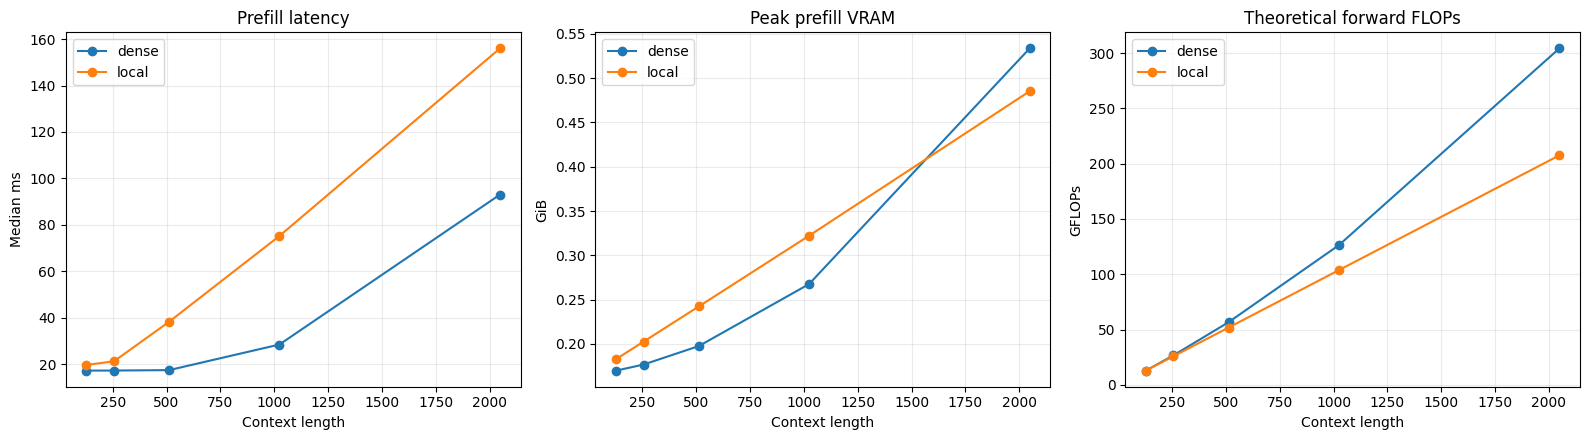

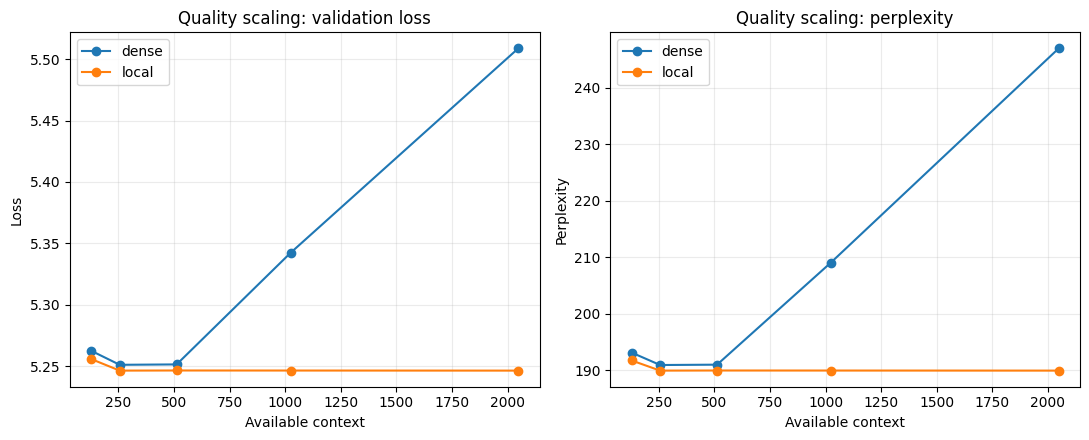

,seed,attention_type,context_length,positions_sha256,validation_loss,perplexity,target_positions,batches_processed
0,42,dense,128,14c056555cef9a12436309131d4bc696cfd757c01404c5...,5.310938,202.540053,128,64
1,42,dense,256,14c056555cef9a12436309131d4bc696cfd757c01404c5...,5.295682,199.473660,128,64
2,42,dense,512,14c056555cef9a12436309131d4bc696cfd757c01404c5...,5.295478,199.432842,128,64
3,42,dense,1024,14c056555cef9a12436309131d4bc696cfd757c01404c5...,5.377386,216.455656,128,64
4,42,dense,2048,14c056555cef9a12436309131d4bc696cfd757c01404c5...,5.515245,248.450823,128,64
5,42,local,128,14c056555cef9a12436309131d4bc696cfd757c01404c5...,5.264033,193.259384,128,64
6,42,local,256,14c056555cef9a12436309131d4bc696cfd757c01404c5...,5.256793,191.865265,128,64
7,42,local,512,14c056555cef9a12436309131d4bc696cfd757c01404c5...,5.256707,191.848629,128,64
8,42,local,1024,14c056555cef9a12436309131d4bc696cfd757c01404c5...,5.256713,191.849910,128,64
9,42,local,2048,14c056555cef9a12436309131d4bc696cfd757c01404c5...,5.256443,191.797955,128,64


,attention_type,context_length,validation_loss_mean,validation_loss_std,perplexity_mean,perplexity_std
0,dense,128,5.262673,0.042856,193.115602,8.354176
1,dense,256,5.251296,0.040641,190.918923,7.807131
2,dense,512,5.251612,0.041252,190.982382,7.910473
3,dense,1024,5.342315,0.032079,209.067958,6.740162
4,dense,2048,5.508629,0.045988,246.985872,11.300157
5,local,128,5.255956,0.015779,191.720596,3.011442
6,local,256,5.246574,0.015272,189.929134,2.888131
7,local,512,5.246673,0.015294,189.948135,2.892554
8,local,1024,5.246634,0.015242,189.940527,2.882708
9,local,2048,5.246570,0.015266,189.928533,2.886939


Saved: /content/drive/MyDrive/efficient_transformer_research/figures/computational_scaling_colab_raschka_v1.png
Saved: /content/drive/MyDrive/efficient_transformer_research/figures/quality_scaling_colab_raschka_v1.png


In [14]:
def fixed_validation_positions(tokens, max_context, target_count):
    first = max_context
    last = tokens.numel() - 1
    assert last > first
    positions = np.linspace(first, last, num=min(target_count, last - first + 1), dtype=np.int64)
    return np.unique(positions)


@torch.inference_mode()
def context_quality(model, tokens, positions, context_length):
    loss_sum = 0.0
    targets_processed = 0
    batches_processed = 0
    for start in range(0, len(positions), cfg.batch_size):
        batch_positions = positions[start : start + cfg.batch_size]
        sequences = torch.stack([
            tokens[int(position) - context_length : int(position) + 1].long()
            for position in batch_positions
        ]).to(DEVICE)
        x = sequences[:, :-1]
        targets = sequences[:, -1]
        with autocast_context():
            logits = model(x)["logits"][:, -1, :]
            loss = F.cross_entropy(logits, targets, reduction="sum")
        loss_sum += float(loss)
        targets_processed += len(batch_positions)
        batches_processed += 1
    mean_loss = loss_sum / targets_processed
    return {
        "validation_loss": mean_loss,
        "perplexity": float(math.exp(min(20.0, mean_loss))),
        "target_positions": targets_processed,
        "batches_processed": batches_processed,
    }


quality_positions = fixed_validation_positions(
    valid_tokens, max(BENCHMARK_LENGTHS), cfg.quality_scaling_targets
)
positions_hash = hashlib.sha256(quality_positions.tobytes()).hexdigest()
(PROJECT_DIR / "results" / f"quality_positions_{RUN_MODE}_{EXPERIMENT_VERSION}.json").write_text(
    json.dumps({
        "positions": quality_positions.tolist(),
        "sha256": positions_hash,
        "validation_tokens_after_tokenization": valid_tokens.numel(),
    }, ensure_ascii=False, indent=2),
    encoding="utf-8",
)


def quality_scaling_seed(seed: int, pair):
    path = PROJECT_DIR / "results" / f"quality_scaling_{RUN_MODE}_{EXPERIMENT_VERSION}_seed{seed}.csv"
    if path.exists() and not RETEST_EXISTING:
        return pd.read_csv(path)

    rows = []
    for attention_type in ("dense", "local"):
        model = load_model_from_checkpoint(pair[attention_type]["checkpoint"])
        for length in BENCHMARK_LENGTHS:
            result = context_quality(model, valid_tokens, quality_positions, length)
            rows.append({
                "seed": seed,
                "attention_type": attention_type,
                "context_length": length,
                "positions_sha256": positions_hash,
                **result,
            })
        del model
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    table = pd.DataFrame(rows)
    table.to_csv(path, index=False)
    return table


quality_scaling_table = pd.concat([
    quality_scaling_seed(seed, pair) for seed, pair in summaries_by_seed.items()
], ignore_index=True)
quality_scaling_table.to_csv(
    PROJECT_DIR / "results" / f"quality_scaling_{RUN_MODE}_{EXPERIMENT_VERSION}.csv",
    index=False,
)

compute_aggregate = benchmark_table.groupby(
    ["attention_type", "context_length"], as_index=False
).agg(
    prefill_latency_ms_median=("prefill_latency_ms_median", "mean"),
    prefill_latency_ms_seed_std=("prefill_latency_ms_median", "std"),
    peak_prefill_vram_bytes=("peak_prefill_vram_bytes", "mean"),
    total_forward_flops=("total_forward_flops", "mean"),
)
quality_scaling_aggregate = quality_scaling_table.groupby(
    ["attention_type", "context_length"], as_index=False
).agg(
    validation_loss_mean=("validation_loss", "mean"),
    validation_loss_std=("validation_loss", "std"),
    perplexity_mean=("perplexity", "mean"),
    perplexity_std=("perplexity", "std"),
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for attention_type, group in compute_aggregate.groupby("attention_type"):
    axes[0].plot(group["context_length"], group["prefill_latency_ms_median"], marker="o", label=attention_type)
    axes[1].plot(group["context_length"], group["peak_prefill_vram_bytes"] / 2**30, marker="o", label=attention_type)
    axes[2].plot(group["context_length"], group["total_forward_flops"] / 1e9, marker="o", label=attention_type)
axes[0].set(title="Prefill latency", xlabel="Context length", ylabel="Median ms")
axes[1].set(title="Peak prefill VRAM", xlabel="Context length", ylabel="GiB")
axes[2].set(title="Theoretical forward FLOPs", xlabel="Context length", ylabel="GFLOPs")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
fig.tight_layout()
compute_figure = PROJECT_DIR / "figures" / f"computational_scaling_{RUN_MODE}_{EXPERIMENT_VERSION}.png"
fig.savefig(compute_figure, dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for attention_type, group in quality_scaling_aggregate.groupby("attention_type"):
    axes[0].plot(group["context_length"], group["validation_loss_mean"], marker="o", label=attention_type)
    axes[1].plot(group["context_length"], group["perplexity_mean"], marker="o", label=attention_type)
axes[0].set(title="Quality scaling: validation loss", xlabel="Available context", ylabel="Loss")
axes[1].set(title="Quality scaling: perplexity", xlabel="Available context", ylabel="Perplexity")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
fig.tight_layout()
quality_figure = PROJECT_DIR / "figures" / f"quality_scaling_{RUN_MODE}_{EXPERIMENT_VERSION}.png"
fig.savefig(quality_figure, dpi=180, bbox_inches="tight")
plt.show()

display(quality_scaling_table)
display(quality_scaling_aggregate)
print("Saved:", compute_figure)
print("Saved:", quality_figure)


In [15]:
def records(frame):
    return json.loads(frame.to_json(orient="records"))


completed_seeds = sorted(summaries_by_seed)
three_seed_complete = completed_seeds == list(REQUIRED_SEEDS)
research_mode = RUN_MODE in ("colab", "full")
report_kind = "final" if (not research_mode or three_seed_complete) else "interim"

final_report = {
    "report_kind": report_kind,
    "pilot_experiment": True,
    "methodology": {
        "book": "Sebastian Raschka, Build a Large Language Model (From Scratch)",
        "chapters": [2, 3, 4, 5],
        "supplements": ["GPT to Llama", "KV cache", "Sliding Window Attention"],
        "official_repository": "https://github.com/rasbt/LLMs-from-scratch",
    },
    "experiment_version": EXPERIMENT_VERSION,
    "environment": {
        "platform": platform.platform(),
        "python": platform.python_version(),
        "pytorch": torch.__version__,
        "cuda": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    },
    "run_config": asdict(cfg),
    "required_seeds": list(REQUIRED_SEEDS),
    "completed_seeds": completed_seeds,
    "three_seed_complete": three_seed_complete,
    "tokenization": {
        "train": train_encoding_stats,
        "validation": validation_encoding_stats,
    },
    "loader_accounting": loader_stats,
    "quality_runs": records(quality_runs),
    "paired_quality": records(paired_quality),
    "lambada": records(lambada_table),
    "lambada_paired_intervals": [payload["paired"] for payload in lambada_payloads],
    "computational_scaling": records(benchmark_table),
    "decode": records(decode_table),
    "quality_scaling": records(quality_scaling_table),
    "quality_positions_sha256": positions_hash,
}

report_path = PROJECT_DIR / "results" / (
    f"{report_kind}_report_{RUN_MODE}_{EXPERIMENT_VERSION}.json"
)
report_path.write_text(json.dumps(final_report, ensure_ascii=False, indent=2), encoding="utf-8")
print("Report:", report_path)
if research_mode and not three_seed_complete:
    print("Research report is interim. Run missing seeds:", sorted(set(REQUIRED_SEEDS) - set(completed_seeds)))


Report: /content/drive/MyDrive/efficient_transformer_research/results/final_report_colab_raschka_v1.json


## Рекомендуемый запуск на бесплатном Colab

1. Выполнить `smoke` для проверки кода.
2. Выбрать `RUN_MODE="colab"` и запускать по одному seed: 42, затем 43, затем 44.
3. Каждый seed обучает Dense и Local примерно на 8,4 млн токенов и выполняет весь набор метрик.
4. Каждые 500 optimizer steps состояние сохраняется в `checkpoints/progress_*.pt`. После обрыва достаточно снова нажать **«Выполнить все»** с тем же seed.
5. После seed 44 повторно выполнить аналитические ячейки. Появится `final_report_colab_raschka_v1.json`.

`full` с 50 млн токенов на модель сохранён для более мощной или платной площадки. Режим `colab` является полным пилотным протоколом: три seed, весь LAMBADA, полная выбранная validation-выборка, интервалы неопределённости, prefill/decode и два вида scaling.
